<a href="https://colab.research.google.com/github/zk025815-beep/HCCDA-AI-Course/blob/main/NLP_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sms+spam+collection.zip to sms+spam+collection (2).zip


In [ ]:
import zipfile
import os

with zipfile.ZipFile("sms+spam+collection.zip", "r") as zip_ref:
    zip_ref.extractall("sms_dataset")

print(os.listdir("sms_dataset"))

['SMSSpamCollection', 'readme']


In [ ]:

df = pd.read_csv(
    "sms_dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
print("Dataset shape:", df.shape)

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5572, 2)

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


In [ ]:
X = df["message"]
y = df["label"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5572,)
Target shape: (5572,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training messages: 4457
Testing messages: 1115

Training label distribution:
label
ham     3859
spam     598
Name: count, dtype: int64

Testing label distribution:
label
ham     966
spam    149
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4457, 7668)
Testing data shape: (1115, 7668)


In [ ]:
print("Example SMS:")
print(X_train.iloc[0])

print("\nTF-IDF representation:")
print(X_train_tfidf[0])

Example SMS:
He will, you guys close?

TF-IDF representation:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5 stored elements and shape (1, 7668)>
  Coords	Values
  (0, 3373)	0.4114937543245475
  (0, 7439)	0.3449147101637941
  (0, 7629)	0.20665147747321655
  (0, 3290)	0.544310621752537
  (0, 1861)	0.6105144115989549


In [ ]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test_tfidf)

print("Actual labels:")
print(y_test.head(10).tolist())

print("\nPredicted labels:")
print(y_pred[:10])

Actual labels:
['ham', 'ham', 'ham', 'spam', 'ham', 'ham', 'ham', 'ham', 'ham', 'ham']

Predicted labels:
['ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


Accuracy: 0.9605381165919282

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.70      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115



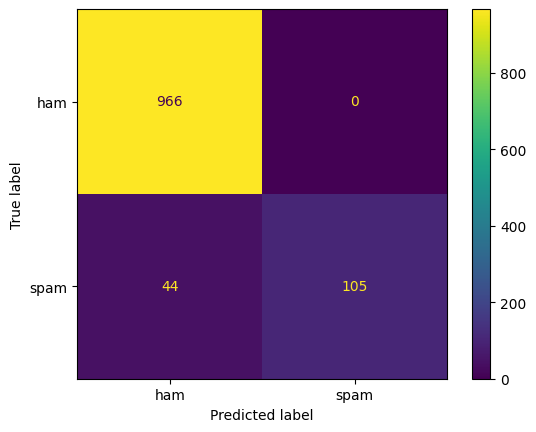

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["ham", "spam"]
)

disp.plot()
plt.show()

In [ ]:
new_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting at 5 pm today?"
]

new_messages_tfidf = tfidf.transform(new_messages)
predictions = model.predict(new_messages_tfidf)

for message, prediction in zip(new_messages, predictions):
    print(f"Message: {message}")
    print(f"Prediction: {prediction}\n")

Message: Congratulations! You have won a free prize. Call now!
Prediction: spam

Message: Hey, are we meeting at 5 pm today?
Prediction: ham



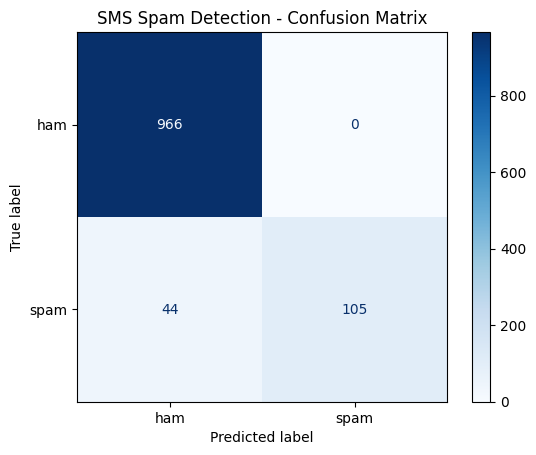

[[966   0]
 [ 44 105]]


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["ham", "spam"]
)

disp.plot(cmap="Blues")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

print(cm)